In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Load & read the data

In [190]:
df = pd.read_csv(r"C:\Users\HP\Downloads\prod_data.csv") 

In [191]:
df.head()

,Order_ID,Order_Date,Product_ID,Product_Category,Demand_Qty,Stock_Available,Units_To_Produce,Production_Capacity,Machine_ID,Shift,Priority,Material_Available,Planned_Start_Date,Actual_Start_Date,Actual_End_Date,Production_Days,Lead_Time_Days
0,ORD000001,2023-04-08,P023,Assembly,233,142,91,128,MC01,Day,Medium,Yes,2023-04-14,2023-04-14,2023-04-15,1,6
1,ORD000002,2025-04-27,P027,Packaging,346,77,269,239,MC01,Day,High,Yes,2025-05-03,2025-05-04,2025-05-06,2,7
2,ORD000003,2024-12-17,P018,Plastic,264,52,212,132,MC02,Day,High,Yes,2024-12-21,2024-12-21,2024-12-25,4,4
3,ORD000004,2024-04-25,P013,Plastic,343,181,162,315,MC05,Evening,Low,Yes,2024-05-02,2024-05-02,2024-05-06,4,7
4,ORD000005,2024-04-19,P001,Mechanical,689,489,200,470,MC06,Day,Medium,Yes,2024-04-23,2024-04-23,2024-04-25,2,4


# 2. Checking data quality

In [192]:
# Check data types
df.dtypes

Order_ID                 str
Order_Date               str
Product_ID               str
Product_Category         str
Demand_Qty             int64
Stock_Available        int64
Units_To_Produce       int64
Production_Capacity    int64
Machine_ID               str
Shift                    str
Priority                 str
Material_Available       str
Planned_Start_Date       str
Actual_Start_Date        str
Actual_End_Date          str
Production_Days        int64
Lead_Time_Days         int64
dtype: object

In [193]:
# Convert datetime frame

date_columns = ["Order_Date","Planned_Start_Date","Actual_Start_Date","Actual_End_Date"]

for col in date_columns:
    df[col] = pd.to_datetime(df[col], errors = "coerce")

In [194]:
# Check data types
df.dtypes

Order_ID                          str
Order_Date             datetime64[us]
Product_ID                        str
Product_Category                  str
Demand_Qty                      int64
Stock_Available                 int64
Units_To_Produce                int64
Production_Capacity             int64
Machine_ID                        str
Shift                             str
Priority                          str
Material_Available                str
Planned_Start_Date     datetime64[us]
Actual_Start_Date      datetime64[us]
Actual_End_Date        datetime64[us]
Production_Days                 int64
Lead_Time_Days                  int64
dtype: object

In [195]:
# Check missing values
print("Missing Values :")
df.isnull().sum()

Missing Values :


Order_ID               0
Order_Date             0
Product_ID             0
Product_Category       0
Demand_Qty             0
Stock_Available        0
Units_To_Produce       0
Production_Capacity    0
Machine_ID             0
Shift                  0
Priority               0
Material_Available     0
Planned_Start_Date     0
Actual_Start_Date      0
Actual_End_Date        0
Production_Days        0
Lead_Time_Days         0
dtype: int64

In [196]:
# Check duplicate rows 
print("Duplicate rows :")
df.duplicated().sum()

Duplicate rows :


np.int64(0)

In [197]:
# Check Statistical summary
print("Numerical summary :")
print(df.describe())

Numerical summary :
                       Order_Date     Demand_Qty  Stock_Available  \
count                      100000  100000.000000    100000.000000   
mean   2024-06-30 20:16:26.400000     457.707400       217.267110   
min           2023-01-01 00:00:00      63.000000         0.000000   
25%           2023-10-01 00:00:00     329.000000       103.000000   
50%           2024-07-02 00:00:00     476.000000       178.000000   
75%           2025-03-31 00:00:00     618.000000       331.000000   
max           2025-12-30 00:00:00     794.000000       668.000000   
std                           NaN     171.802448       145.985878   

       Units_To_Produce  Production_Capacity          Planned_Start_Date  \
count     100000.000000        100000.000000                      100000   
mean         240.483880           299.770410  2024-07-07 00:52:17.184000   
min            1.000000           100.000000         2023-01-02 00:00:00   
25%          159.000000           200.000000         2

In [198]:
# Unique products and categories
print("Unique Products :",df["Product_ID"].nunique())
print("\nProduct Categories :")
print(df["Product_Category"].value_counts())

Unique Products : 30

Product Categories :
Product_Category
Assembly      20071
Packaging     20052
Plastic       20046
Electrical    20035
Mechanical    19796
Name: count, dtype: int64


In [199]:
# Checking priority 
print("Priority Distribution :")
print(df["Priority"].value_counts())

Priority Distribution :
Priority
Medium    45111
Low       24827
High      24038
Urgent     6024
Name: count, dtype: int64


In [200]:
# Now check all information
print("Data Information")
print(df.info())

# Shape of dataset
print("\nShape of Dataset :",df.shape)

Data Information
<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 17 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Order_ID             100000 non-null  str           
 1   Order_Date           100000 non-null  datetime64[us]
 2   Product_ID           100000 non-null  str           
 3   Product_Category     100000 non-null  str           
 4   Demand_Qty           100000 non-null  int64         
 5   Stock_Available      100000 non-null  int64         
 6   Units_To_Produce     100000 non-null  int64         
 7   Production_Capacity  100000 non-null  int64         
 8   Machine_ID           100000 non-null  str           
 9   Shift                100000 non-null  str           
 10  Priority             100000 non-null  str           
 11  Material_Available   100000 non-null  str           
 12  Planned_Start_Date   100000 non-null  datetime64[us]
 13  Actual_St

# 3. Visualization of production pattern

In [201]:
df.columns.tolist()

['Order_ID',
 'Order_Date',
 'Product_ID',
 'Product_Category',
 'Demand_Qty',
 'Stock_Available',
 'Units_To_Produce',
 'Production_Capacity',
 'Machine_ID',
 'Shift',
 'Priority',
 'Material_Available',
 'Planned_Start_Date',
 'Actual_Start_Date',
 'Actual_End_Date',
 'Production_Days',
 'Lead_Time_Days']

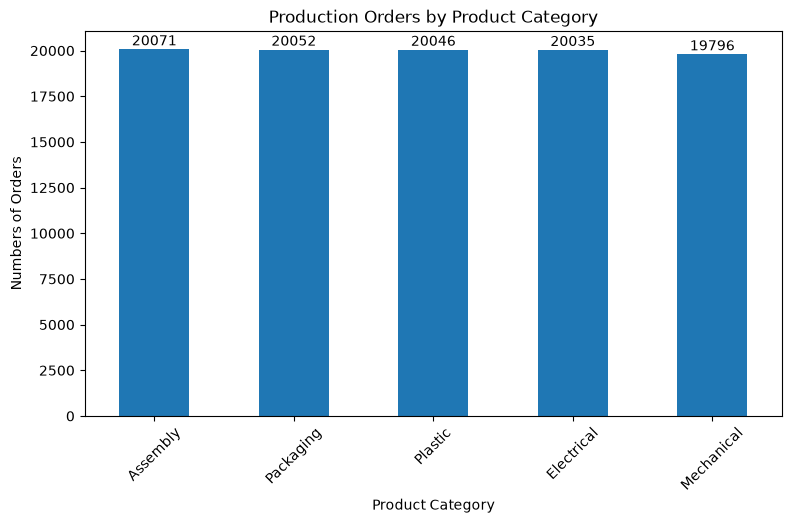

In [202]:
# 1. No of orders by production category
plt.figure(figsize=(9,5))
fig = df["Product_Category"].value_counts().plot(kind = "bar")

plt.title("Production Orders by Product Category")
plt.xlabel("Product Category")
plt.ylabel("Numbers of Orders")
plt.xticks(rotation=45)
fig.bar_label(fig.containers[0],padding = 0.5)
plt.show()

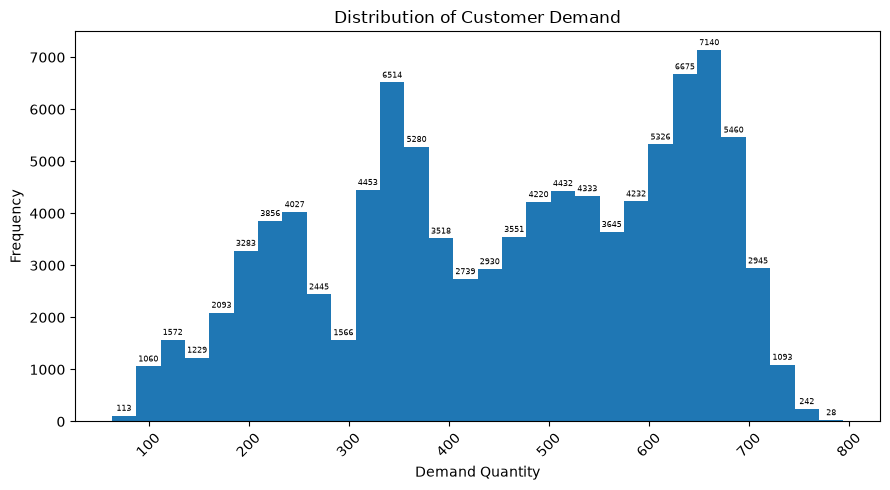

In [203]:
# 2. Demand quantity distribution
plt.figure(figsize=(9,5))
n, bins, patches = plt.hist(df["Demand_Qty"], bins = 30)

plt.title("Distribution of Customer Demand")
plt.xlabel("Demand Quantity")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.bar_label(patches, padding=2, fmt="%.0f", fontsize=6)
plt.tight_layout()
plt.show()

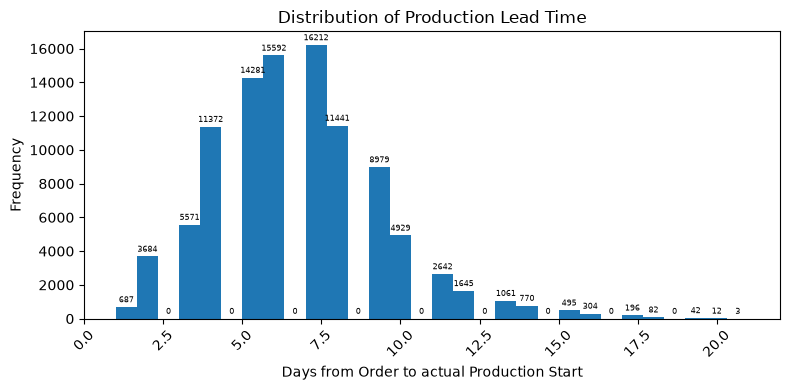

In [204]:
# 3. Production Lead time

plt.figure(figsize=(8,4))
n, bins, patches = plt.hist(df["Lead_Time_Days"], bins = 30)

plt.title("Distribution of Production Lead Time")
plt.xlabel("Days from Order to actual Production Start")
plt.ylabel("Frequency")
plt.xticks(rotation=45)
plt.bar_label(patches, padding=2, fmt="%.0f", fontsize=6)
plt.tight_layout()
plt.show()

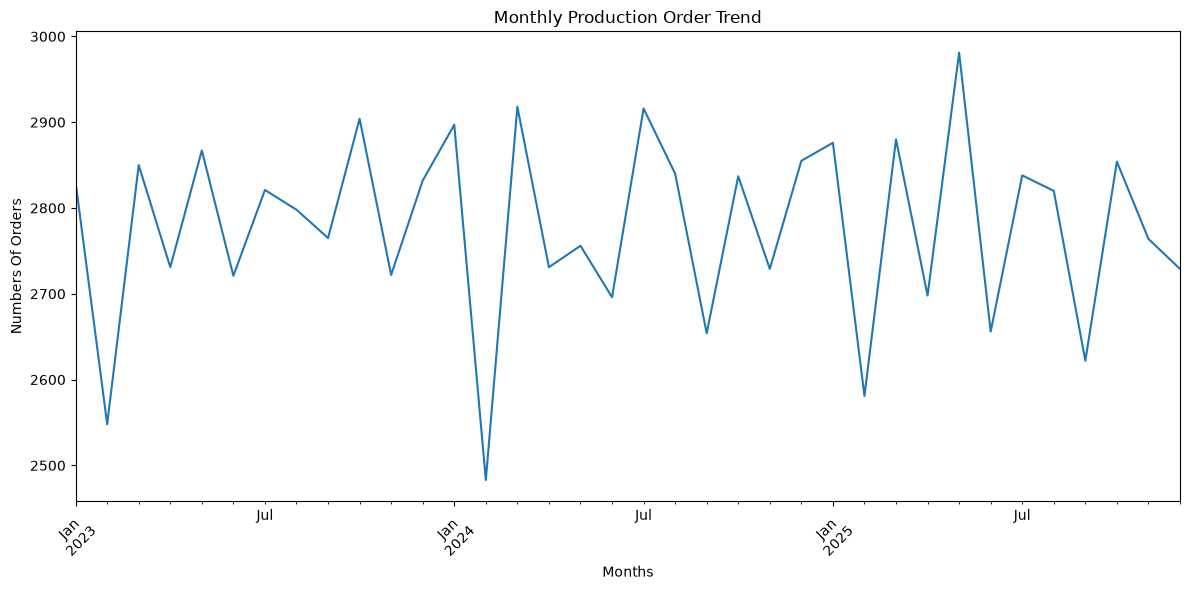

In [205]:
# 4. Monthly Production Trend
monthly_orders = (df.set_index("Order_Date").resample("MS")["Order_ID"].count())

monthly_orders.plot(figsize=(12,6))
plt.title("Monthly Production Order Trend")
plt.xlabel("Months")
plt.ylabel("Numbers Of Orders")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# 4. Feature Engineering

In [206]:
df.columns.tolist()

['Order_ID',
 'Order_Date',
 'Product_ID',
 'Product_Category',
 'Demand_Qty',
 'Stock_Available',
 'Units_To_Produce',
 'Production_Capacity',
 'Machine_ID',
 'Shift',
 'Priority',
 'Material_Available',
 'Planned_Start_Date',
 'Actual_Start_Date',
 'Actual_End_Date',
 'Production_Days',
 'Lead_Time_Days']

In [207]:
# Cration dataset features
df["Order_Year"] = df["Order_Date"].dt.year
df["Order_Month"] = df["Order_Date"].dt.month
df["Order_Days"] = df["Order_Date"].dt.day
df["Order_Day_Of_week"] = df["Order_Date"].dt.dayofweek

# Panned Start delay
df["Planned_Start_Delay"] = (df["Planned_Start_Date"]-df["Order_Date"]).dt.days

# Display new features
nf = df[["Order_Year","Order_Month","Order_Days","Order_Day_Of_week","Planned_Start_Delay"]]
print(nf.head())

   Order_Year  Order_Month  Order_Days  Order_Day_Of_week  Planned_Start_Delay
0        2023            4           8                  5                    6
1        2025            4          27                  6                    6
2        2024           12          17                  1                    4
3        2024            4          25                  3                    7
4        2024            4          19                  4                    4


In [208]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 22 columns):
 #   Column               Non-Null Count   Dtype         
---  ------               --------------   -----         
 0   Order_ID             100000 non-null  str           
 1   Order_Date           100000 non-null  datetime64[us]
 2   Product_ID           100000 non-null  str           
 3   Product_Category     100000 non-null  str           
 4   Demand_Qty           100000 non-null  int64         
 5   Stock_Available      100000 non-null  int64         
 6   Units_To_Produce     100000 non-null  int64         
 7   Production_Capacity  100000 non-null  int64         
 8   Machine_ID           100000 non-null  str           
 9   Shift                100000 non-null  str           
 10  Priority             100000 non-null  str           
 11  Material_Available   100000 non-null  str           
 12  Planned_Start_Date   100000 non-null  datetime64[us]
 13  Actual_Start_Date    10000

In [209]:
# Target variable
target = "Lead_Time_Days"

# Numerical feature columns 
num_fea = ['Demand_Qty' ,'Stock_Available', 'Units_To_Produce', 'Production_Capacity', 'Order_Year', 
           'Order_Month', 'Order_Days', 'Order_Day_Of_week', 'Planned_Start_Delay']

# Categorical feature columns 
cat_fea = ['Product_Category', 'Machine_ID', 'Shift', 'Priority', 'Material_Available']

features = num_fea + cat_fea

X = df[features]
y = df[target]

print("Input Feature Shape : ", X.shape)
print("\nTarget Shape : ", y.shape)
print("\nTarget Summary :\n", y.describe())

Input Feature Shape :  (100000, 14)

Target Shape :  (100000,)

Target Summary :
 count    100000.000000
mean          6.618990
std           2.668433
min           1.000000
25%           5.000000
50%           6.000000
75%           8.000000
max          21.000000
Name: Lead_Time_Days, dtype: float64


In [210]:
# Import libraries for train test
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import accuracy_score, mean_absolute_error, mean_squared_error, r2_score



In [211]:
# Sorting order date
df_sorted = df.sort_values("Order_Date").reset_index(drop=True)

X = df_sorted[features]
y = df_sorted[target]

In [212]:
# Training(80%) and testing (20%)

split_index = int(len(df_sorted) * 0.80)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]

y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

print("X_train Training Data Size  : ",X_train.shape)
print("\nX_test Testing Data Size : ",X_test.shape)
print("\ny_train Training Data Size : ",y_train.shape)
print("\ny_test Testing Data Size : ",y_test.shape)

X_train Training Data Size  :  (80000, 14)

X_test Testing Data Size :  (20000, 14)

y_train Training Data Size :  (80000,)

y_test Testing Data Size :  (20000,)


In [213]:
# Encoding categorical features 

preprocessor = ColumnTransformer(
    transformers = [
        ("categorical",OneHotEncoder(handle_unknown="ignore"),cat_fea),
        ("numerical", "passthrough", num_fea)
    ])

# Creating Pipeline
model = Pipeline([
    ("preprocessor", preprocessor),
    ("regressor", RandomForestRegressor(n_estimators = 100, random_state = 42, n_jobs = -1))
])

# Train the model
model.fit(X_train, y_train)


,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('preprocessor', ...), ('regressor', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Only defined if theunderlying estimator exposes such an attribute when fit... versionadded:: 1.0","ndarray[object](14,)","['Demand_Qty','Stock_Available','Units_To_Produce',...,'Shift','Priority', 'Material_Available']"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`. Only defined if theunderlying first estimator in `steps` exposes such an attributewhen fit... versionadded:: 0.24,int,14
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('categorical', ...), ('numerical', ...)]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatic

In [214]:
# Feature Evalution
y_pred = model.predict(X_test)

# Evaluation performance

mae = mean_absolute_error(y_test, y_pred)
mse = mean_squared_error(y_test, y_pred)
rmse = np.sqrt(mse)
r2 = r2_score(y_test, y_pred)

print("Model Evalution Result :")
print("-"*40)
print(f"\nMean Absolute Error : {mae:.3f} Days")
print(f"\nMean Squared Error : {mse:.3f} ")
print(f"\nRoot Mean Squared Error : {rmse:.3f} Days")
print(f"\nR2 Score : {r2:.3f}")


Model Evalution Result :
----------------------------------------

Mean Absolute Error : 0.696 Days

Mean Squared Error : 0.743 

Root Mean Squared Error : 0.862 Days

R2 Score : 0.895


In [217]:
# Compare with baseline model
from sklearn.dummy import DummyRegressor

baseline = DummyRegressor(strategy="mean")
baseline.fit(X_train, y_train)

baseline_pred = baseline.predict(X_test)

base_mae = mean_absolute_error(y_test, baseline_pred)
base_mse = mean_squared_error(y_test, baseline_pred)
base_rmse = np.sqrt(mse)
base_r2 = r2_score(y_test, baseline_pred)

print("Baseline Model Evalution Result :")
print("-"*40)
print(f"\nBaseline Mean Absolute Error : {base_mae:.3f} Days")
print(f"\nBaseline  Squared Error : {base_mse:.3f} ")
print(f"\nBaseline Baseline Root Mean Squared Error : {base_rmse:.3f} Days")
print(f"\nBaseline R2 Score : {base_r2:.3f}")


Baseline Model Evalution Result :
----------------------------------------

Baseline Mean Absolute Error : 2.069 Days

Baseline  Squared Error : 7.088 

Baseline Baseline Root Mean Squared Error : 0.862 Days

Baseline R2 Score : -0.000


Our model perform much better than baseline model

In [218]:
# Feature importance
rf_model = model.named_steps["regressor"]

# Get feature names
feature_names = (model.named_steps["preprocessor"].get_feature_names_out())

# Create Feature importance dataframe
importance_df = pd.DataFrame({"feature":feature_names, "Importance":rf_model.feature_importances_})

# Sort highest to lowest
importance_df = importance_df.sort_values(by="Importance", ascending = False)

# Display Top 15 features
print(importance_df.head(15))

                           feature  Importance
28  numerical__Planned_Start_Delay    0.901257
23  numerical__Production_Capacity    0.015347
22     numerical__Units_To_Produce    0.013180
20           numerical__Demand_Qty    0.012695
21      numerical__Stock_Available    0.012449
26           numerical__Order_Days    0.010328
25          numerical__Order_Month    0.007221
27    numerical__Order_Day_Of_week    0.005632
24           numerical__Order_Year    0.002650
7     categorical__Machine_ID_MC03    0.001341
11          categorical__Shift_Day    0.001330
9     categorical__Machine_ID_MC05    0.001305
8     categorical__Machine_ID_MC04    0.001293
5     categorical__Machine_ID_MC01    0.001288
6     categorical__Machine_ID_MC02    0.001287


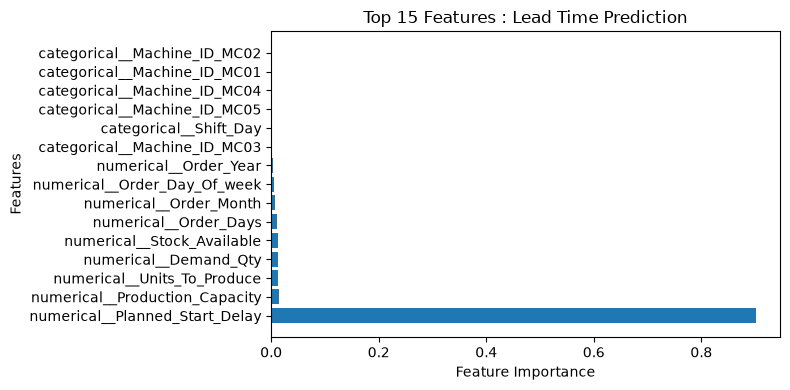

In [219]:
# Visualize the top features 
top_features = importance_df.head(15).sort_values(by="Importance", ascending = False)

plt.figure(figsize=(8,4))

plt.barh(top_features["feature"],top_features["Importance"])

plt.title("Top 15 Features : Lead Time Prediction")
plt.xlabel("Feature Importance")
plt.ylabel("Features")
plt.tight_layout()
plt.show()

In [220]:
# Check Data leakage
print("Target : ",target)

print("\nInput Features :")
print(X.columns.tolist())

print("\nColumns Excluded from Input Features :")\

excluded_col = [
    col for col in df.columns
    if col not in X.columns and col != target]

print(excluded_col )

Target :  Lead_Time_Days

Input Features :
['Demand_Qty', 'Stock_Available', 'Units_To_Produce', 'Production_Capacity', 'Order_Year', 'Order_Month', 'Order_Days', 'Order_Day_Of_week', 'Planned_Start_Delay', 'Product_Category', 'Machine_ID', 'Shift', 'Priority', 'Material_Available']

Columns Excluded from Input Features :
['Order_ID', 'Order_Date', 'Product_ID', 'Planned_Start_Date', 'Actual_Start_Date', 'Actual_End_Date', 'Production_Days']


In [221]:
# Check relationship between planned delay and target

print("Planned Start Delay Summary:")
print(df["Planned_Start_Delay"].describe())

print("\nLead Time Summary:")
print(df["Lead_Time_Days"].describe())

print("\nCorrelation:")

print(df[["Planned_Start_Delay", "Lead_Time_Days"]].corr())

print("\nSample comparison:")
print(df[["Order_Date","Planned_Start_Date","Planned_Start_Delay","Lead_Time_Days"]].head(15))

Planned Start Delay Summary:
count    100000.000000
mean          6.191560
std           2.534129
min           1.000000
25%           4.000000
50%           6.000000
75%           8.000000
max          20.000000
Name: Planned_Start_Delay, dtype: float64

Lead Time Summary:
count    100000.000000
mean          6.618990
std           2.668433
min           1.000000
25%           5.000000
50%           6.000000
75%           8.000000
max          21.000000
Name: Lead_Time_Days, dtype: float64

Correlation:
                     Planned_Start_Delay  Lead_Time_Days
Planned_Start_Delay             1.000000        0.949398
Lead_Time_Days                  0.949398        1.000000

Sample comparison:
   Order_Date Planned_Start_Date  Planned_Start_Delay  Lead_Time_Days
0  2023-04-08         2023-04-14                    6               6
1  2025-04-27         2025-05-03                    6               7
2  2024-12-17         2024-12-21                    4               4
3  2024-04-25      

In [222]:
# Build a second model

# Remove Planned_Start_Delay from numerical features

num_fea_no_delay = [col for col in num_fea if col !="Planned_Start_Delay"]

features_no_delay = num_fea_no_delay + cat_fea

X_no_delay = df[features_no_delay]
y = df["Lead_Time_Days"]

X_train2, X_test2, y_train2, y_test2 = train_test_split(X_no_delay, y, test_size = 0.2, random_state = 42)

preprocessor2 = ColumnTransformer(
    transformers = [
        ("categorical",OneHotEncoder(handle_unknown="ignore"),cat_fea),
        ("numerical", "passthrough", num_fea_no_delay)
    ])

# Train the second model 
model_no_delay = Pipeline([
    ("preprocessor2", preprocessor2),
    ("regressor", RandomForestRegressor(n_estimators = 100, random_state = 42, n_jobs = -1))
])

# Train the model
model_no_delay.fit(X_train2, y_train2)

y_pred2 = model_no_delay.predict(X_test2)

# Evaluation performance

mae_no_delay = mean_absolute_error(y_test2, y_pred2)
mse_no_delay = mean_squared_error(y_test2, y_pred2)
rmse_no_delay = np.sqrt(mse_no_delay)
r2_no_delay = r2_score(y_test2, y_pred2)

print("Model Evalution Result without Planned_Start_Delay :")
print("-"*40)
print(f"\nMean Absolute Error : {mae_no_delay:.3f} Days")
print(f"\nMean Squared Error : {mse_no_delay:.3f} ")
print(f"\nRoot Mean Squared Error : {rmse_no_delay:.3f} Days")
print(f"\nR2 Score : {r2_no_delay:.3f}")

Model Evalution Result without Planned_Start_Delay :
----------------------------------------

Mean Absolute Error : 1.246 Days

Mean Squared Error : 2.392 

Root Mean Squared Error : 1.546 Days

R2 Score : 0.668


In [226]:
# Now we predict the lead time days

new_order = pd.DataFrame([{
    "Demand_Qty": 400,
    "Stock_Available": 100,
    "Units_To_Produce": 300,
    "Production_Capacity": 350,
    "Order_Year": 2026,
    "Order_Month": 10,
    "Order_Days": 11,
    "Order_Day_Of_week": 6,
    "Product_Category": "Electronics",
    "Machine_ID": "MC01",
    "Shift": "Day",
    "Priority": "High",
    "Material_Available": "Yes",
    "Planned_Start_Delay": 3
}])

# Make a Prediction
print("Preduction using model_no_delay which dont have Planned_Start_Delay column :")
predicted_lead_time = model_no_delay.predict(new_order)
print("Predictd Lead Time : ", round(predicted_lead_time[0], 2), "Days")

print("\nPreduction using model which have Planned_Start_Delay column :")
predicted_lead_time2 = model.predict(new_order)
print("Predictd Lead Time : ", round(predicted_lead_time2[0], 2), "Days")

Preduction using model_no_delay which dont have Planned_Start_Delay column :
Predictd Lead Time :  3.97 Days

Preduction using model which have Planned_Start_Delay column :
Predictd Lead Time :  3.44 Days


In [231]:
# Compare actual vs predicted values

comparison = pd.DataFrame({"Actual_Lead_Time":y_test2,"Predicted_Lead_Time":y_pred})

comparison["Absolute_Error"] = (comparison["Actual_Lead_Time"] - comparison["Predicted_Lead_Time"]).abs()

print(comparison.head(10).round(2))

       Actual_Lead_Time  Predicted_Lead_Time  Absolute_Error
75721                 8                 8.37            0.37
80184                 4                 2.48            1.52
19864                 2                 6.28            4.28
76699                 6                 2.53            3.47
92991                 5                 9.57            4.57
76434                 4                 7.61            3.61
84004                 8                 2.09            5.91
80917                12                 5.34            6.66
60767                 5                 7.33            2.33
50074                 9                 3.32            5.68


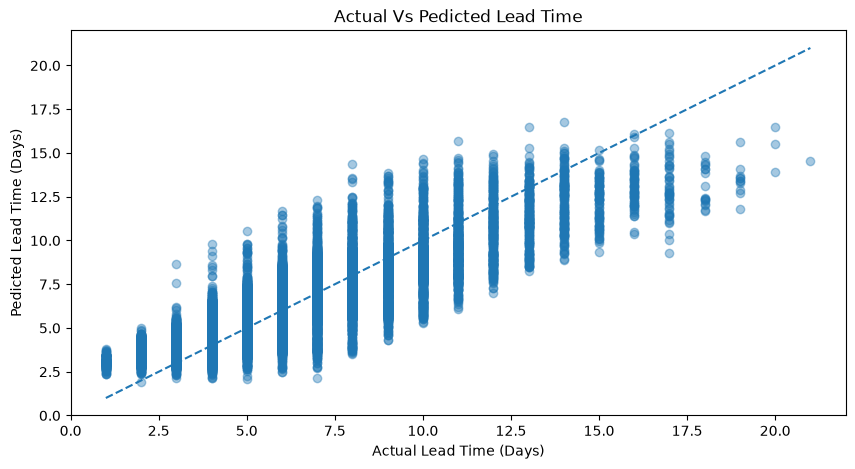

In [236]:
plt.figure(figsize=(10,5))

plt.scatter(y_test2, y_pred2, alpha = 0.4)

plt.plot([y_test2.min(), y_test2.max()],[y_test2.min(), y_test2.max()],linestyle = "--")

plt.title("Actual Vs Pedicted Lead Time")
plt.xlabel("Actual Lead Time (Days)")
plt.ylabel("Pedicted Lead Time (Days)")
plt.show()

In [250]:
import joblib
# Save model without Planned_Delay_Days 
joblib.dump(model_no_delay, "Manufacturing_lead_time_calculator_model_2.pkl")

# Save Feature Name
joblib.dump(X_train2.columns.tolist(), "Manufacturing_lead_time_calculator_feature_2.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [251]:
import joblib
# Save model with Planned_Delay_Days 
joblib.dump(model, "Manufacturing_lead_time_calculator_model_1.pkl")

# Save Feature Name
joblib.dump(X_train.columns.tolist(), "Manufacturing_lead_time_calculator_feature_1.pkl")

print("Model Saved Successfully")

Model Saved Successfully


In [253]:
import joblib
import pandas as pd

model_no_delay = joblib.load(
    "Manufacturing_lead_time_calculator_model_2.pkl"
)

features = joblib.load(
    "Manufacturing_lead_time_calculator_feature_2.pkl"
)

print("Model loaded successfully!\n")
print("Required features:", features)

Model loaded successfully!

Required features: ['Demand_Qty', 'Stock_Available', 'Units_To_Produce', 'Production_Capacity', 'Order_Year', 'Order_Month', 'Order_Days', 'Order_Day_Of_week', 'Product_Category', 'Machine_ID', 'Shift', 'Priority', 'Material_Available']


In [256]:
new_order = pd.DataFrame([{
    "Demand_Qty": 500,
    "Stock_Available": 100,
    "Units_To_Produce": 400,
    "Production_Capacity": 150,
    "Order_Year": 2026,
    "Order_Month": 10,
    "Order_Days": 11,
    "Order_Day_Of_week": 6,
    "Product_Category": "Electronics",
    "Machine_ID": "M001",
    "Shift": "Morning",
    "Priority": "High",
    "Material_Available": "Yes"
}])

new_order = new_order[features]

predicted_days = model_no_delay.predict(new_order)

print("Predicted Produstion lead time : ",round(predicted_days[0], 2), "Days")
    

Predicted Produstion lead time :  6.09 Days
